# **Indian Interim Union Budget 2024-2025 Analysis**


## 📖 1. Motive / Backstory
The **Union Budget of India** is the most highly anticipated economic event of the year. Delivered by the Hon'ble Finance Minister in the Parliament, this comprehensive speech doesn't just allocate funds—it sets the economic narrative, defines the government's priorities, and influences market sentiment for the entire fiscal year. 

However, a 30 to 40-page technical speech can be overwhelming to digest manually. While news channels provide summarized highlights, the raw, authentic tone and granular focus of the government often get lost in media interpretation. As data enthusiasts, we can leverage **Natural Language Processing (NLP)** to bypass the noise, directly analyze the authentic Parliamentary text, and let the data reveal the true focus of the budget.

---

## 🏛️ 2. Understanding the Context: Interim vs. Full Union Budget
Since **2024 was a Lok Sabha Election year**, two separate budgets were presented in the Parliament. Understanding this distinction is crucial for context:

### What is an Interim Budget?
An **Interim Budget** is a temporary financial arrangement presented by the ruling government when general elections are due. Under **Article 116 of the Indian Constitution**, a mechanism called **"Vote on Account"** is passed:
* **Purpose:** It authorizes the government to incur necessary expenses (salaries, ongoing projects, administrative costs) for a transition period (typically 2 to 4 months) until the new government is elected and assumes office.
* **Limitations:** The outgoing government strictly avoids announcing major policy shifts, introducing new tax slabs, or rolling out massive welfare schemes that could influence voter sentiment during election campaigning.
* **Narrative Focus:** Instead of radical changes, the speech primarily reflects a review of the past 5 to 10 years of economic governance, fiscal prudence, and outlines a broad strategic vision (e.g., *Viksit Bharat*).

### Interim Budget vs. Full Union Budget at a Glance

| Feature | Interim Budget (February) | Full Union Budget (July) |
| :--- | :--- | :--- |
| **Timing** | Presented before General Elections | Presented after the new government forms |
| **Validity** | Short-term (covers 2–4 months) | Full financial year (12 months) |
| **Tax Proposals** | Generally untouched / no major reforms | Major tax reforms, slab changes, exemptions |
| **Policy Scope** | Administrative continuity; no mega-schemes | Full policy roadmap, sector allocations, fiscal deficit targets |

> *For this analysis, we focus on the **Full Union Budget 2024–25 (July 2024)**, as it contains the newly elected government's definitive 5-year developmental roadmap, revised tax regimes, and full sector-wise allocations.*

---

## 🎯 3. Problem Statement
**Objective:** To systematically analyze the Union Budget Speech of India using Natural Language Processing (NLP) to extract underlying sentiments, dominant themes, and key sector priorities.

**Specific Goals of this Project:**
1. **Automated Extraction:** Fetch and parse the authentic budget speech document directly from the official India Budget portal.
2. **Text Processing (Cleaning):** Standardize the raw text by removing stop words, legal jargon, and punctuations to prepare a clean corpus.
3. **Thematic EDA:** Identify the most frequently emphasized words and sectors (e.g., Agriculture, Technology, Infrastructure, Employment) to visualize the government's core focus areas using WordClouds and Frequency Plots.
4. **Sentiment & Tone Analysis:** Apply sentiment analysis to understand the emotional trajectory of the speech—identifying whether the overall tone is optimistic (growth-oriented), neutral (factual allocations), or cautious (focusing on inflation/deficits).

### **Library Importation**

In [40]:
pip install openai

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 19.9 MB/s  0:00:00

   ---------------------------------------- 0/6 [truststore]
  Attempting uninstall: idna
   ---------------------------------------- 0/6 [truststore]
    Found existing installation: idna 3.11
   ---------------------------------------- 0/6 [truststore]
    Uninstalling idna-3.11:
   ---------------------------------------- 0/6 [truststore]
      Successfully uninstalled idna-3.11
   ---------------------------------------- 0/6 [truststore]
   ------------- -------------------------- 2/6 [idna]
   ------------- -------------------------- 2/6 [idna]
   ------------- -------------------------- 2/6 [idna]
   -------------------- ------------------- 3/6 [httpcore2]
   -------------------- ------------------- 3/6 [httpcore2]
   -------------------- ------------------- 3/6 [httpcore2]
   -------------------- ------------------- 3/6 [httpcore2]
   --

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph 1.1.9 requires langgraph-sdk<0.4.0,>=0.3.0, but you have langgraph-sdk 0.4.5 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import numpy as np
import pandas as pd
import requests
import os
import pypdf
import seaborn as sns
import nltk
import string
import ollama
import matplotlib.pyplot as plt
from google import genai
from google.genai import types
from docx import Document
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from scipy import stats
from dotenv import load_dotenv
from groq import Groq

import warnings
warnings.filterwarnings("ignore")


In [2]:
import nltk
import ssl


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt')
nltk.download('punkt_tab') 
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:

url = "https://www.indiabudget.gov.in/doc/bspeech/bs2024_25(I).pdf"
file_name = "Budget_Speech_2024-25_Interim.pdf"

headers = {"User-Agent": "Mozilla/5.0"}
res = requests.get(url, headers=headers)

if res.status_code == 200:
    with open(file_name, "wb") as f:
        f.write(res.content)
    print("Downloaded.")
else:
    print(f"Fetch failed: {res.status_code}")

li = []
if os.path.exists(file_name):
    reader = pypdf.PdfReader(file_name)
    for page in reader.pages:
        text = page.extract_text()
        if text:
            paras = [p.strip() for p in text.split('\n') if len(p.strip()) > 30]
            li.extend(paras)

    print(f"Extracted {len(li)} paragraphs.")
else:
    print("File missing.")


Downloaded.
Extracted 551 paragraphs.


In [4]:
import pypdf

# PDF read karne ke liye
reader = pypdf.PdfReader(file_name)
li = []

for page in reader.pages:
    text = page.extract_text()
    if text:
        # Paragraphs ko break karke clean text nikaalna
        for p in text.split("\n"):
            p = p.strip()
            if len(p) > 25:  # chhote headers/page numbers filter karne ke liye
                li.append(p)

print(f"\n✅ Extraction Complete! The speech contains {len(li)} paragraphs.")
print("\n--- Initial Look at Data ---")
print(li[:2])


✅ Extraction Complete! The speech contains 577 paragraphs.

--- Initial Look at Data ---
['Inclusive Development and Growth  2', 'Exemplary Track Record of Governance,']


In [5]:
stop_words = set(stopwords.words("english"))
budget_fillers = {
    'madam', 'speaker', 'sir', 'honble', 'hon', 'ble', 'house', 'parliament', 
    'members', 'member', 'table', 'present', 'speech', 'beg', 'leave',

    'crore', 'crores', 'lakh', 'lakhs', 'rupee', 'rupees', 'rs', 'inr', 
    'per', 'cent', 'percent', 'percentage', 'rate', 'rates', 'amount', 
    'estimated', 'estimates', 'total', 'approx', 'number', 'level',

    'propose', 'proposed', 'proposes', 'proposing', 'proposal', 'proposals',
    'provide', 'provided', 'provides', 'providing', 'provision', 'provisions',
    'announce', 'announced', 'announces', 'announcing',
    'setup', 'launched', 'launch', 'initiated', 'facilitate', 'facilitating',
    'enhance', 'enhancing', 'undertake', 'undertaken', 'continue', 'continued',
    'assist', 'assistance', 'support', 'enable', 'implement', 'implemented',

    'act', 'section', 'sub', 'clause', 'clauses', 'subsection', 'amend', 
    'amended', 'amendment', 'amendments', 'schedule', 'notification', 
    'notified', 'prescribed', 'applicable', 'regime', 'exemption', 
    'deduction', 'assessment', 'specified', 'respect', 'matter', 'regard',

    'government', 'gov', 'budget', 'union', 'central', 'state', 'states',
    'year', 'years', 'financial', 'fy', 'period', 'annual', 'current', 
    'next', 'past', 'time', 'day', 'month', 'months', 'phase',
    'also', 'well', 'like', 'part', 'para', 'annexure', 'various', 
    'across', 'including', 'included', 'basis', 'terms', 'manner', 'measures'
}

custom_stop_words = stop_words.union(budget_fillers)

In [6]:
def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = ''.join([i for i in text if not i.isdigit()])
    

    y = word_tokenize(text)

    cleaned_text = [w for w in y if w not in custom_stop_words and len(w) > 2]

    return " ".join(cleaned_text)


clean_paras = [clean_text(q) for q in li]

full_cleaned_Speech = " ".join(clean_paras)


print("Data Cleaning Completed")

print("Cleaned preview:", clean_paras[10][:100],"....")

Data Cleaning Completed
Cleaned preview: indian economy witnessed profound positive ....


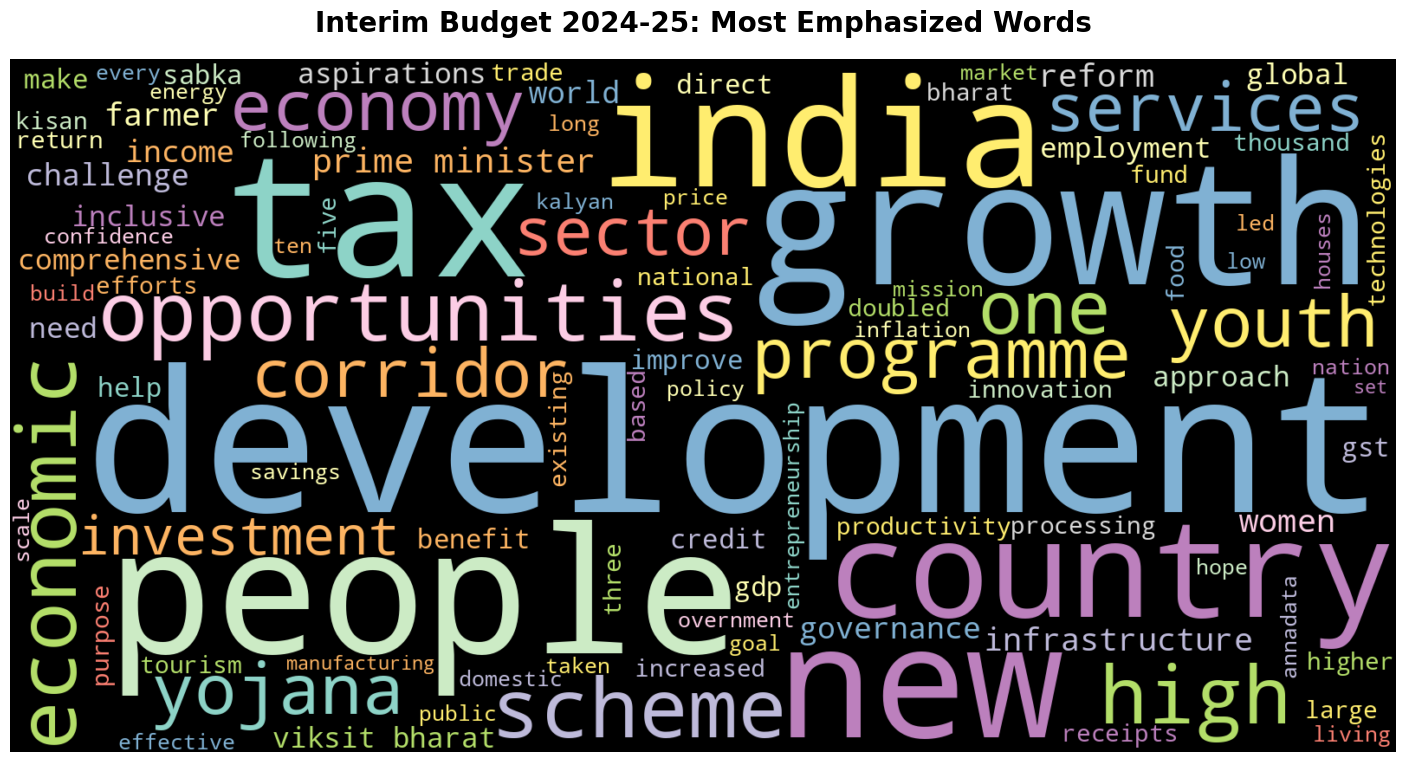

In [10]:
plt.figure(figsize=(18,9))
cloud = WordCloud(width=1600,height=800,background_color="black", colormap='Set3', max_words=101).generate(full_cleaned_Speech)
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Interim Budget 2024-25: Most Emphasized Words", fontsize=20, fontweight='bold', pad=20)
plt.show()

In [11]:
ls = full_cleaned_Speech.split()
cnt = Counter(ls)
top10 = cnt.most_common(10)

df = pd.DataFrame(top10, columns=['Word', 'Frequency'])
df

,Word,Frequency
0,development,32
1,tax,28
2,people,25
3,growth,24
4,new,20
5,india,18
6,country,16
7,opportunities,15
8,economic,15
9,high,14


In [12]:
bigrams = ngrams(ls,2)
bigrams_freq = Counter(bigrams)


top10_bigrams = bigrams_freq.most_common(10)
bigrams_data = {"Bigrams" : [f"{q[0][0]} {q[0][1]}" for q in top10_bigrams],
                "Count" : [q[1] for q in top10_bigrams]}


df_bigrams = pd.DataFrame(bigrams_data)
df_bigrams

,Bigrams,Count
0,prime minister,10
1,viksit bharat,7
2,exemplary track,4
3,track record,4
4,vision viksit,4
5,amrit kaal,4
6,interest free,4
7,inclusive development,3
8,record governance,3
9,governance development,3


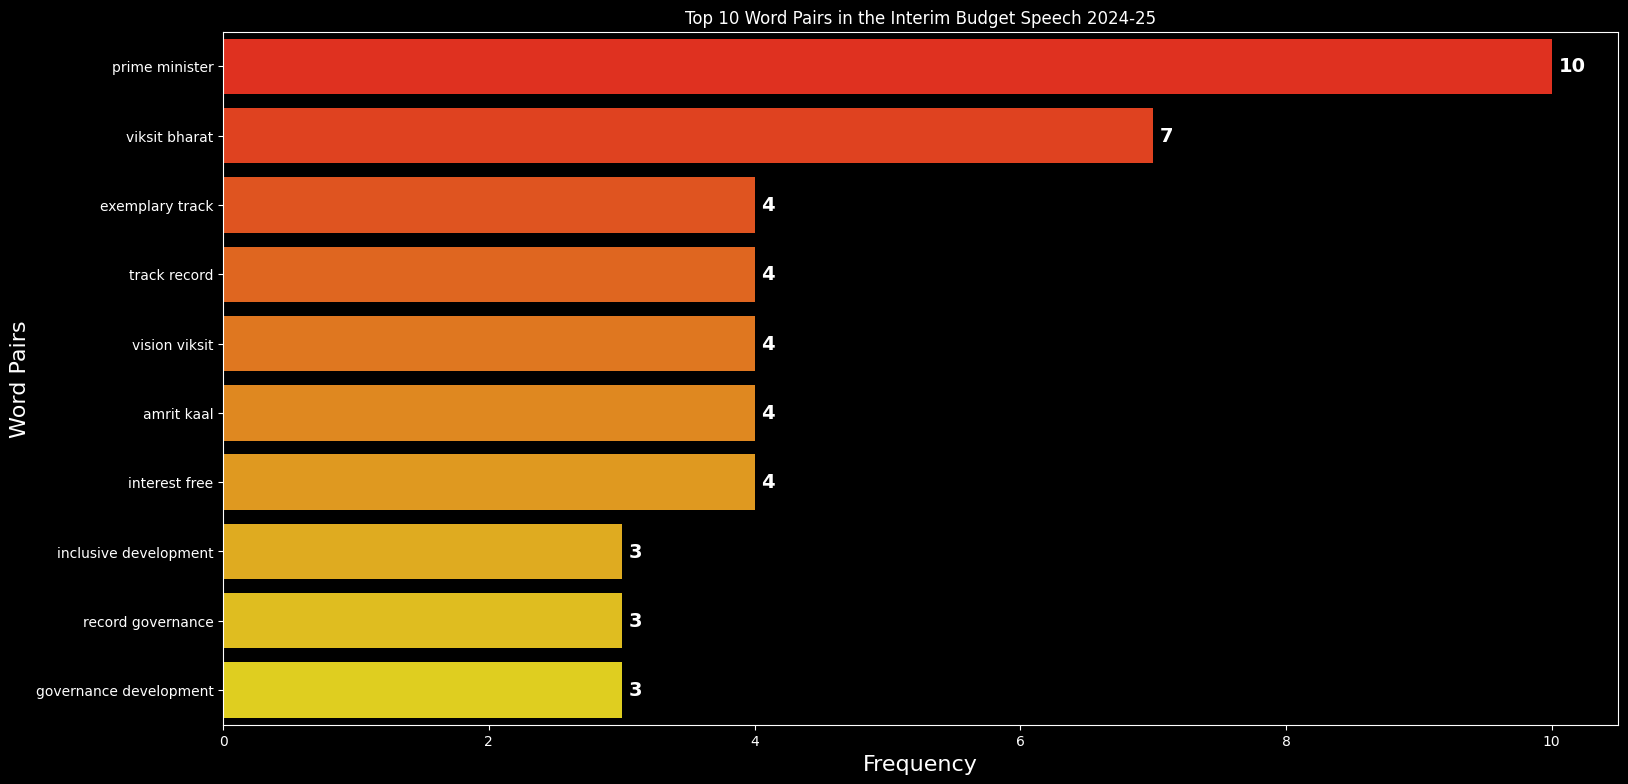

In [13]:
plt.style.use("dark_background") 

plt.figure(figsize=(18,9))
bar = sns.barplot(x="Count", y="Bigrams", data=df_bigrams, palette="autumn")

for i in bar.containers:

    bar.bar_label(i, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title('Top 10 Word Pairs in the Interim Budget Speech 2024-25')
plt.xlabel("Frequency", fontsize=16)
plt.ylabel("Word Pairs", fontsize=16)
plt.show()

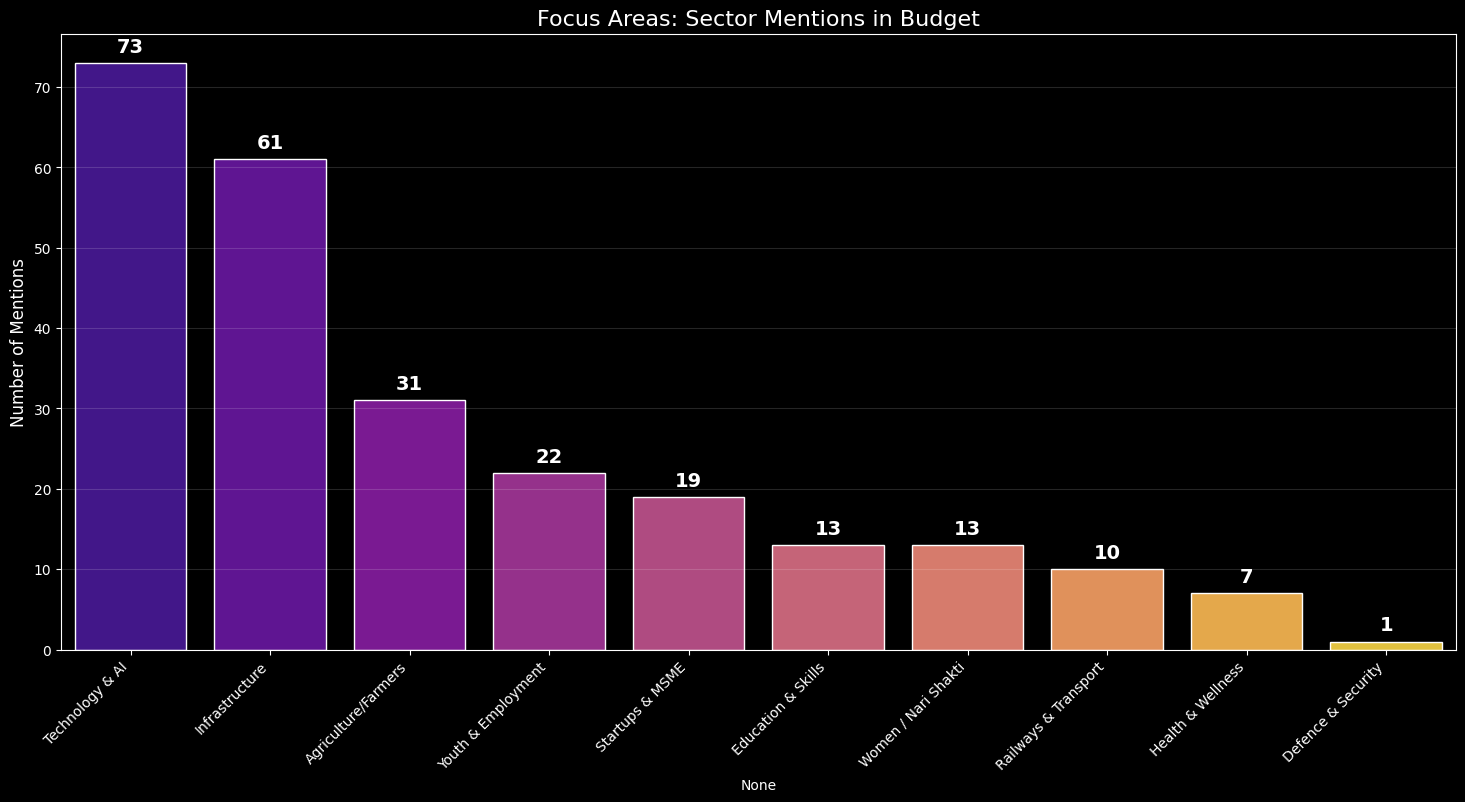

In [14]:
sec = {
    'Agriculture/Farmers': ['agriculture', 'farmer', 'farmers', 'kisan', 'crop', 'crops', 'rural', 'irrigation'],
    'Education & Skills': ['education', 'school', 'schools', 'college', 'university', 'students', 'learning', 'skill', 'skills'],
    'Health & Wellness': ['health', 'hospital', 'hospitals', 'medical', 'disease', 'vaccine', 'nutrition', 'ayushman'],
    'Railways & Transport': ['rail', 'railway', 'railways', 'train', 'trains', 'vande bharat', 'station', 'metro'],
    'Technology & AI': ['technology', 'digital', 'tech', 'ai', 'innovation', 'artificial intelligence', 'research'],
    'Defence & Security': ['defence', 'military', 'army', 'navy', 'airforce', 'armed forces', 'border'],
    'Women / Nari Shakti': ['women', 'woman', 'girl', 'girls', 'nari', 'shakti', 'mahila', 'matru'],
    'Youth & Employment': ['youth', 'young', 'employment', 'jobs', 'job', 'rozgar', 'career'],
    'Startups & MSME': ['startup', 'startups', 'msme', 'msmes', 'entrepreneur', 'entrepreneurship', 'business', 'businesses'],
    'Infrastructure': ['infrastructure', 'infra', 'roads', 'highway', 'highways', 'bridge', 'bridges', 'port', 'ports', 'aviation']
}

dict = {}

for sector_name, word_list in sec.items():
    total = 0
    for word in word_list:
        total += full_cleaned_Speech.count(word)
    dict[sector_name] = total

df_sec = pd.Series(dict).sort_values(ascending=False)

plt.figure(figsize=(18,8))
ax = sns.barplot(x=df_sec.index, y=df_sec.values, palette='plasma', edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title("Focus Areas: Sector Mentions in Budget", fontsize=16)
plt.ylabel("Number of Mentions", fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.15)
plt.style.use('dark_background')
plt.show()

In [15]:
lt = []

for i in clean_paras:
    if len(i) > 10:
        blob = TextBlob(i)

        lt.append(blob.sentiment.polarity)


df_sentiments = pd.DataFrame(lt, columns=['Polarity'])

avg_sentiment = df_sentiments["Polarity"].mean()




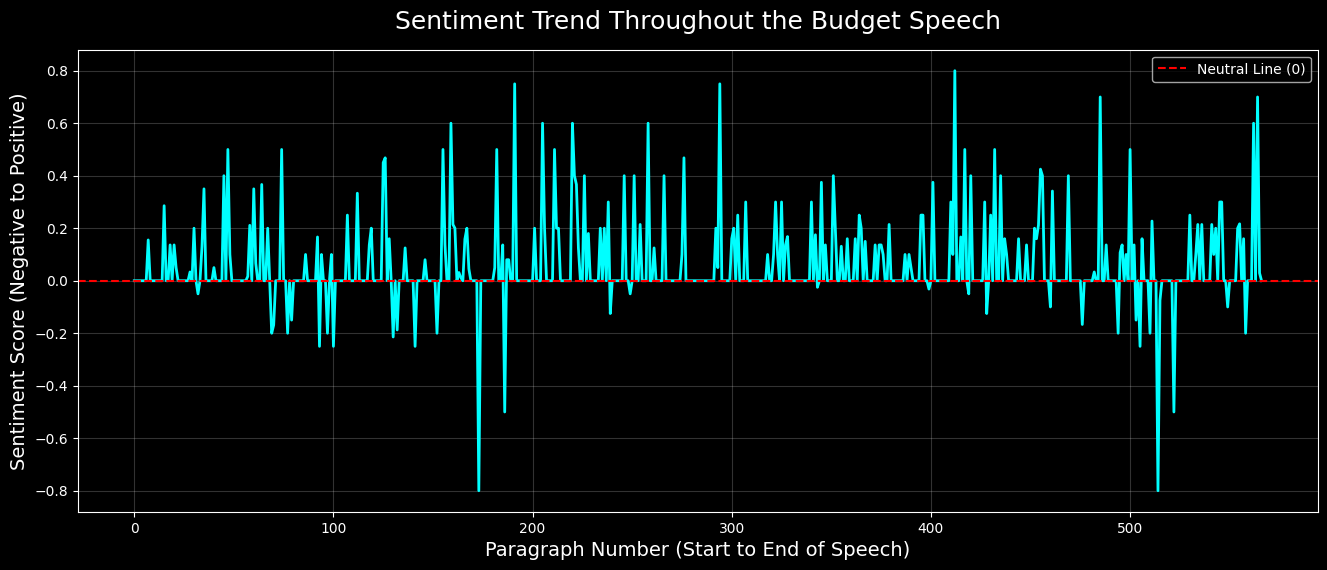

Sentiment Analysis Results
---------------------------------------------
Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: 0.055


In [16]:
plt.figure(figsize=(16, 6))
plt.plot(df_sentiments['Polarity'], color='cyan', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Neutral Line (0)')
plt.title("Sentiment Trend Throughout the Budget Speech", fontsize=18, pad=15)
plt.xlabel("Paragraph Number (Start to End of Speech)", fontsize=14)
plt.ylabel("Sentiment Score (Negative to Positive)", fontsize=14)
plt.legend()
plt.grid(alpha=0.2)
plt.style.use('dark_background')
plt.show()


print('Sentiment Analysis Results')
print("-"*45)
if avg_sentiment > 0.05:
        print(f"Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: {avg_sentiment:.3f}")
elif avg_sentiment < -0.05:
    print(f"Overall Tone: CAUTIOUS / NEGATIVE | Score: {avg_sentiment:.3f}")
else:
    print(f"Overall Tone: NEUTRAL (Factual/Balanced) | Score: {avg_sentiment:.3f}")

In [17]:
desc_stats = df_sentiments[['Polarity']].describe().T.round(3)

desc_stats.columns = ['Total Paragraphs', 'Average (Mean)', 'Std Dev', 'Minimum', '25%', 'Median', '75%', 'Maximum']
desc_stats.index = ['Sentiment Tone']

desc_stats

,Total Paragraphs,Average (Mean),Std Dev,Minimum,25%,Median,75%,Maximum
Sentiment Tone,567.0,0.055,0.16,-0.8,0.0,0.0,0.073,0.8


In [18]:
mp = len(df_sentiments)//2

hf1 = df_sentiments['Polarity'][:mp]
hf2 = df_sentiments['Polarity'][mp:]

print(f"First Half Average Sentiment: {hf1.mean():.3f}")
print(f"Second Half Average Sentiment: {hf2.mean():.3f}")


t_stat, pval = stats.ttest_ind(hf1, hf2)

print(f'''T-Test hypothesis 
Test Statistic Value = {t_stat:.4f}
P Value = {pval:.4f}''')


if pval < 0.05:

    print("\nConclusion: P-value is lower 0.05 threshold.")
    print("This refers to that we have a significant difference between tone of first half and second half")
else:
    print("\nConclusion: P-value is higher than 0.05 threshold.")
    print("This refers to that we don't have a significant difference between tone of first half and second half")



First Half Average Sentiment: 0.050
Second Half Average Sentiment: 0.060
T-Test hypothesis 
Test Statistic Value = -0.7430
P Value = 0.4578

Conclusion: P-value is higher than 0.05 threshold.
This refers to that we don't have a significant difference between tone of first half and second half


In [19]:
from IPython.display import display, Markdown

def model_eval(model, text_data):

    print(f"{model.upper()} is analyzing the budget......")

    # Aapka exact same prompt, maine isme 1 word bhi change nahi kiya hai
    prompt =f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 

Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections:

### 1. Sector-Wise Allocations & Focus
Provide a detailed breakdown of what specific announcements, funds, or policies were made for the following 10 sectors. (If a sector was not significantly mentioned, state "Limited mentions"):
- Agriculture & Farmers
- Education & Skills
- Health & Wellness
- Railways & Transport
- Technology & AI
- Defence & Security
- Women / Nari Shakti
- Youth & Employment
- Startups & MSME
- Infrastructure

### 2. The 'Rupee Comes From' Analysis (Revenue)
Explain the government's revenue model. If the government earns 100 Rupees, break down exactly where this money is coming from (e.g., Corporate Tax, Income Tax, GST, Borrowings, Non-tax revenue, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Explain the government's expenditure model. If the government spends 100 Rupees, break down exactly where it is going (e.g., Interest Payments, Defence, Subsidies, State shares, Pensions, Central Sector Schemes, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

Format your response clearly using Markdown, bold text for key numbers, and bullet points. Do not hallucinate; use only the data present in the text provided below.

---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        response = ollama.chat(model=model, messages=[{'role' : "user", "content" :prompt}])
        print(f'\n {model.upper()} Budget Analysis')
        print("=" * 60)
        
        # YAHAN CHANGE KIYA HAI: print() hata diya, aur display(Markdown()) laga diya
        # Issey Output scrollable nahi aayega, balki professional formatted aayega
        display(Markdown(response['message']['content']))
        
        print("=" * 60 + "\n")

    except Exception as e:
        print("ERROR with Ollama Models therefore Kindly Check Again..............")

In [20]:
budget_doc = " ".join(li)
model_eval('phi3', budget_doc )

PHI3 is analyzing the budget......

 PHI3 Budget Analysis


Given the extensive and ambitious agricultural, dairy, fisheries, technological, infrastructural, tourism, and environmental schemes outlined in the speech, I will now present a structured table summarizing the key points of the comprehensive plan for the Indian economy and the steps taken to strengthen various sectors as articulated in the document:


| Key Points/Sector | Proposed Actions/Initiatives |
|------------------|-------------------------|
| Agriculture | Improve livestock productivity, modernize farming techniques, market linkages, and value addition. Launch integrated dairy development programme leveraging existing schemes. Implement PMMSY to double aquaculture production and employment. |
| Livestock | Control foot and mouth disease, expand dairy farming, and provide capital for infrastructure and processing facilities. |
| Fisheries | Double exports to ` 1 lakh crore, set up integrated aquaparks, expand the fisheries sector, and provide loans for deep-tech technologies. |
| Women Empowerment | Acknowledge the success of SHGs, enhance targets for Lakhpati Didi, and provide interest-free loans for capital expenditure. |
| Technology & Innovation | Establish a corpus of ` 1 lakh crore for financing research and innovation, promote new age technologies, and expand metro rail and NaMo Bharat. |
| Energy & Infrastructure | Triple capital expenditure outlay, expand railway corridors, and improve logistics efficiency. |
| Health & Safety | Implement safety standards for rail bogies and invest in dedicated freight corridors. |
| Transportation | Expand airport facilities, roll out air connectivity to tier 2 and 3 cities, and provide airport development loans. |
| Renewable Energy | Invest in offshore wind energy, set up coal gasification plants, and mandate CBG blending for transport and PNG for domestic use. |
| Green Growth & Climate Action | Launch schemes for bio-manufacturing, bio-foundry, and carbon capture projects. |
| Tourism | Support comprehensive development of iconic tourist centers, promote domestic tourism, and expand airport infrastructure. |
| Defence & Security | Launch new schemes for deep-tech technologies, expand infrastructure development, and provide financing for private sector scaling up of research and innovation. |
| Taxation | Maintain tax rates, extend tax benefits for startups and investments, and withdraw outdated tax demands to ease taxpayer burden. |
| Economic Growth & Employment | Increase capital expenditure by 11.1% to drive economic growth and reduce fiscal deficit. |
| International Trade | Improve customs processes and reduce import release time at various port facilities. |
| Governance & Investment | Launch bilateral investment treaties, increase FDI inflow, and provide financing for state reforms and goals. |
| Climate Commitment | Launch measures for harnessing offshore wind energy and reduce imports of natural gas. |
| Net-Zero Goal | Implement mandatory CBG blending, promote EV ecosystem, and expand bio-manufacturing and bio-foundry sectors. |


This table provides a structured summary of the key points and initiatives proposed in the speech, providing an overview of the comprehensive plan for strengthening various sectors and driving economic growth in India.

In [21]:
budget_doc = " ".join(li)
model_eval('llama3.1', budget_doc )

LLAMA3.1 is analyzing the budget......

 LLAMA3.1 Budget Analysis


**Section 1: Sector-Wise Allocations & Focus**

Here's a detailed breakdown of the specific announcements, funds, or policies made for each sector:

### Agriculture & Farmers
* **PM-KISAN SAMMAN Yojana**: Direct financial assistance to 11.8 crore farmers, including marginal and small farmers.
* **PM Fasal Bima Yojana**: Crop insurance to 4 crore farmers.
* **Electronic National Agriculture Market**: Integrated 1361 mandis, providing services to 1.8 crore farmers with trading volume of ₹ 3 lakh crore.
* **Atmanirbhar Oil Seeds Abhiyan**: Strategy to achieve 'atmanirbharta' for oil seeds such as mustard, groundnut, sesame, soybean, and sunflower.
* **Pradhan Mantri Kisan Sampada Yojana**: Benefitted 38 lakh farmers and generated 10 lakh employment.
* **Pradhan Mantri Formalisation of Micro Food Processing Enterprises Yojana**: Assisted 2.4 lakh SHGs and sixty thousand individuals with credit linkages.

### Education & Skills
* **National Education Policy 2020**: Transformational reforms.
* **PM ScHools for Rising India (PM SHRI)**: Quality teaching and nurturing holistic and well-rounded individuals.
* **Skill India Mission**: Trained 1.4 crore youth, upskilled and reskilled 54 lakh youth, and established 3000 new ITIs.

### Health & Wellness
* **Cervical Cancer Vaccination**: Encouraging vaccination for girls in age group of 9 to 14 years.
* **Maternal and Child Health Care**: Comprehensive programme for synergy in implementation.
* **Ayushman Bharat scheme**: Extended to all ASHA workers, Anganwadi Workers and Helpers.
* **Healthcare cover**: Extended to all ASHA workers, Anganwadi Workers and Helpers.

### Railways & Transport
* **Three major economic railway corridor programmes**: Energy, mineral and cement corridors, port connectivity corridors, and high traffic density corridors.
* **Forty thousand normal rail bogies to be converted to Vande Bharat standards**: Enhance safety, convenience, and travel speed.
* **Aviation sector**: Expansion of existing airports and development of new airports.

### Technology & AI
* **New scheme for strengthening deep-tech technologies for defence purposes**: Expediting infrastructure development.
* **Bio-manufacturing and bio-foundry scheme**: Provide environment-friendly alternatives.
* **New age technologies and data**: Changing lives of people and businesses, enabling new economic opportunities.

### Defence & Security
* **Strengthening deep-tech technologies for defence purposes**: Expediting infrastructure development.
* **Bio-manufacturing and bio-foundry scheme**: Provide environment-friendly alternatives.

### Women / Nari Shakti
* **Thirty crore Mudra Yojana loans given to women entrepreneurs**: Empowering women through entrepreneurship.
* **Female enrolment in higher education**: Increased by twenty-eight percent in ten years.
* **Girls and women constituting forty-three percent of enrolment in STEM courses**: One of the highest in the world.
* **Women in Lok Sabha and State legislative assemblies**: Reservation of one-third seats.
* **Houses under PM Awas Yojana in rural areas**: Over seventy percent given to women as sole or joint owners.

### Youth & Employment
* **PM Mudra Yojana**: Sanctioned 43 crore loans aggregating to ₹ 22.5 lakh crore for entrepreneurial aspirations of our youth.
* **Fund of Funds, Start Up India, and Start Up Credit Guarantee schemes**: Assisting our youth.
* **Youth becoming 'rozgardata'**: Empowering the youth.

### Startups & MSME
* **Orienting the regulatory environment to facilitate growth**: Encouraging the private sector to scale up research and innovation significantly in sunrise domains.
* **One lakh crore corpus established with fifty-year interest-free loan**: Encouraging the private sector to scale up research and innovation significantly in sunrise domains.

**Section 2: Sector-Wise Allocations & Focus (continued)**

### Infrastructure Development
* **Increased capital expenditure outlay**: 11.1 percent increase to eleven lakh, eleven thousand, one hundred and eleven crore rupees (₹ 11,11,111 crore).
* **Three major economic railway corridor programmes**: Energy, mineral and cement corridors, port connectivity corridors, and high traffic density corridors.
* **Viability gap funding for harnessing offshore wind energy potential**: Initial capacity of 5 GW.
* **Coal gasification and liquefaction capacity of 100 MT by 2030**: Reducing imports of natural gas, methanol, and ammonia.

### Energy
* **Viability gap funding for harnessing offshore wind energy potential**: Initial capacity of 5 GW.
* **Coal gasification and liquefaction capacity of 100 MT by 2030**: Reducing imports of natural gas, methanol, and ammonia.
* **Phased mandatory blending of compressed biogas (CBG) in compressed natural gas (CNG)**: For transport and piped natural gas (PNG) for domestic purposes.

### Environment
* **Bio-manufacturing and bio-foundry scheme**: Provide environment-friendly alternatives.
* **Comprehensive development of tourist centres**: Encouraging states to take up comprehensive development of iconic tourist centres.

**Section 3: Sector-Wise Allocations & Focus (continued)**

### Tourism
* **Comprehensive development of tourist centres**: Encouraging states to take up comprehensive development of iconic tourist centres.
* **Long-term interest-free loans for financing development**: On matching basis.

### Industry & Commerce
* **FDI inflow during 2014-23**: USD 596 billion, marking a golden era.
* **Encouraging sustained foreign investment**: Negotiating bilateral investment treaties with foreign partners.

### States
* **Provision of seventy-five thousand crore rupees as fifty-year interest-free loan**: For supporting milestone-linked reforms by the State Governments.
* **High-powered committee for addressing challenges arising from fast population growth and demographic changes**: Mandated to make recommendations.

**Section 4: Financial Allocation**

### Budget Estimate
* **Revised Estimate of total receipts other than borrowings**: ₹ 27.56 lakh crore.
* **Revised Estimate of total expenditure**: ₹ 47.66 lakh crore.
* **Fiscal deficit**: 5.8 percent of GDP.

### Fiscal Consolidation
* **Continuing on the path of fiscal consolidation**: To reduce fiscal deficit below 4.5 percent by 2025-26.
* **Fiscal deficit in 2024-25**: Estimated to be 5.1 percent of GDP.

**Section 5: Taxation**

### Direct Taxes
* **No changes relating to taxation**: Retaining the same tax rates for direct taxes.
* **Extension of tax benefits to start-ups and investments made by sovereign wealth or pension funds**: Up to 31.03.2025.

### Indirect Taxes
* **No changes relating to taxation**: Retaining the same tax rates for indirect taxes, including import duties.
* **Extension of tax exemption on certain income of some IFSC units**: Up to 31.03.2025.

**Section 6: Taxpayer Services**

### Petty, Non-verified, Non-reconciled or Disputed Direct Tax Demands
* **Withdrawing such outstanding direct tax demands**: Up to ₹ 25,000 for the period up to financial year 2009-10 and up to ₹ 10,000 for financial years 2010-11 to 2014-15.

**Section 7: Conclusion**

The interim budget has allocated funds for various sectors, including agriculture, education, health, railways, technology, defence, women, youth, startups, MSMEs, infrastructure development, energy, environment, tourism, industry, and commerce. The government has also committed to continuing on the path of fiscal consolidation and reducing the fiscal deficit below 4.5 percent by 2025-26.

In [22]:
budget_doc = " ".join(li)
model_eval('qwen2', budget_doc )

QWEN2 is analyzing the budget......

 QWEN2 Budget Analysis


### 1. Sector-Wise Allocations & Focus

**Agriculture & Farmers:** The government has taken initiatives like Pradhan Mantri Kisan Sampada Yojana which has benefited 38 lakh farmers and generated employment opportunities for 10 lakh individuals. Efforts are being made to enhance agricultural productivity through value addition, reducing post-harvest losses, improving productivity and incomes, and encouraging private and public investment in post-harvest activities.

**Education & Skills:** A transformative change is happening through the National Education Policy 2020, and initiatives like PM-Schools for Rising India (PM SHRI) are delivering quality teaching and nurturing holistic development. The Skill India Mission has trained over 1.4 million youth, and PM-Mudra Yojana has provided loans to 43 crore individuals for entrepreneurial aspirations.

**Health & Wellness:** The government aims to ensure comprehensive maternal and child health care by bringing various schemes under one program for synergy. It also plans to provide healthcare coverage to ASHA workers, Anganwadi workers, and helpers under the Ayushman Bharat scheme.

**Railways & Transport:** A comprehensive plan is being developed for infrastructure development including the construction of eight integrated aquaparks, conversion of rail bogies to Vande Bharat standards, and enhancing the aviation sector through the UDAN scheme. 

**Technology & AI:** India's tech-savvy youth are encouraged with opportunities for research and innovation through a one-lakh crore corpus with a fifty-year interest-free loan scheme.

**Defence & Security:** Steps are being taken to double the production of oil seeds and expand the biogas ecosystem. Efforts are also being made to control foot and mouth disease among milch animals.

**Women / Nari Shakti:** Initiatives like Mudra Yojana and PM-Mudra have sanctioned loans to over thirty crore women entrepreneurs. There's focus on skill development, education, and entrepreneurship for women.

**Youth & Employment:** The youth empowerment through education, skill development, entrepreneurship, and employment in sectors like agriculture and technology.

**Startups & MSME:** Government schemes such as Pradhan Mantri Formalisation of Micro Food Processing Enterprises Yojana have assisted 2.4 lakh SHGs and sixty thousand individuals with credit linkages.

**Infrastructure Development:** Plans are in place to improve the infrastructure development through the implementation of three major economic railway corridor programs.

### 2. Revenue & Expenditure

**Revenue Estimates:** The revenue receipts for the revised estimate are ` 30.03 lakh crore, which are expected to be higher than the budget estimate due to strong growth momentum.

**Expenditure Estimates:** The total expenditure is estimated to be ` 47.66 lakh crore. The Revised Estimate of the fiscal deficit is 5.8 per cent of GDP.

**Fiscal Consolidation:** The government continues to aim for fiscal consolidation, reducing the fiscal deficit below 4.5% by 2025-26. Gross and net market borrowings are planned to be lower than the previous year, facilitating larger availability of credit for the private sector.

**Direct Taxes:** Direct tax collections have more than tripled over the last ten years, and the threshold for presumptive taxation for retail businesses was increased from ` 2 crore to ` 3 crore.

**Indirect Taxes & GST:** GST has reduced the compliance burden on trade and industry, with an increase in the industry's view of the transition as largely positive and leading to supply chain optimization. The average monthly gross GST collection has almost doubled to ` 1.66 lakh crore.

**Customs:** Steps have been taken to facilitate international trade, reducing the import release time and enhancing the ease of doing business.

**Tax Proposals:** The tax rates for direct and indirect taxes, including import duties, are proposed to be retained as per convention. Certain tax benefits to start-ups and investments made by sovereign wealth or pension funds are extended until 31.03.2025.

### 3. White Paper & Vision

The government intends to lay a White Paper on the table outlining lessons learned from past mismanagement, governance improvements, and effective delivery systems to realize the vision of 'Viksit Bharat' with good intentions, true dedication, and hard work in the coming years.

In [ ]:
import os
from google import genai
from google.genai import types
from IPython.display import display, Markdown

client = genai.Client(api_key="") # API key is removed due to security reasons

prompt = f"""You are an expert Economic Analyst analyzing the Indian Union Budget 2024-25 Speech. 
Analyze the ENTIRE text below (especially the Budget Estimates, Receipts, and Tax sections) and generate three comprehensive Markdown Tables.

### 1. Sector-Wise Allocations & Focus
Markdown Table: 'Sector' | 'Key Announcements/Allocations'
Cover: Agriculture & Farmers, Education & Skills, Health & Wellness, Railways & Transport, Technology & AI, Defence & Security, Women / Nari Shakti, Youth & Employment, Startups & MSME, Infrastructure. (Provide 2-3 specific points per sector).

### 2. The 'Rupee Comes From' Analysis (Revenue)
Markdown Table: 'Revenue Source' | 'Details/Amount'
Extract from the Receipts, Market Borrowings, and Tax proposals (e.g., Net Tax Receipts, Gross/Net Market Borrowings, Direct Taxes, Customs, GST/Indirect Taxes).

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Markdown Table: 'Expenditure Area' | 'Details/Amount'
Extract from the Total Expenditure, Public Capital Expenditure (Capex), Major Central Schemes, State Grants, etc.

Do not leave sections 2 and 3 empty. Extract all available revenue and expenditure figures from the speech.
---
BUDGET SPEECH TEXT:
{budget_doc}
"""

response = client.models.generate_content(
    model="gemini-flash-lite-latest",
    contents=prompt,
    config=types.GenerateContentConfig(temperature=0.2)
)

print("🌟 COMPLETE BUDGET 2024-25 ANALYSIS 🌟")
print("=" * 60)
display(Markdown(response.text))
print("=" * 60)

🌟 COMPLETE BUDGET 2024-25 ANALYSIS 🌟


### 1. Sector-Wise Allocations & Focus

| Sector | Key Announcements/Allocations |
| :--- | :--- |
| **Agriculture & Farmers** | • Expansion of Nano DAP application across all agro-climatic zones.<br>• Launch of "Atmanirbhar Oil Seeds Abhiyan" for crop self-sufficiency (mustard, groundnut, sesame, soybean, sunflower).<br>• Stepping up implementation of PM Matsya Sampada Yojana and comprehensive support programme for dairy farmers. |
| **Education & Skills** | • NEP 2020 ushering in transformational reforms with PM SHRI schools delivering quality teaching.<br>• Skill India Mission trained 1.4 crore youth, upskilled/reskilled 54 lakh youth, and established 3000 new ITIs.<br>• Establishment of new higher education institutions (7 IITs, 16 IIITs, 7 IIMs, 15 AIIMS, 390 universities). |
| **Health & Wellness** | • Setting up more medical colleges using existing hospital infrastructure via a dedicated committee.<br>• Encouraging vaccination for girls (9-14 years) to prevent cervical cancer.<br>• Extending Ayushman Bharat healthcare cover to all ASHA workers, Anganwadi Workers, and Helpers. |
| **Railways & Transport** | • Implementation of three major economic railway corridor programmes under PM Gati Shakti (energy/mineral/cement, port connectivity, high traffic density).<br>• Conversion of 40,000 normal rail bogies to Vande Bharat standards.<br>• Doubling of airports to 149 and rapid expansion of Metro Rail and NaMo Bharat systems. |
| **Technology & AI** | • Establishment of a ₹1 lakh crore corpus with 50-year interest-free loans to provide long-term financing/refinancing for sunrise domains and deep-tech tech in defence.<br>• Leveraging Digital Public Infrastructure as a new 'factor of production' for economic formalization. |
| **Defence & Security** | • Launch of a new scheme for strengthening deep-tech technologies specifically for defence purposes.<br>• Macro-economic stability and robust national security frameworks integrated into 'Panch Pran' and 'Amrit Kaal'. |
| **Women / Nari Shakti** | • Enhancement of the Lakhpati Didi target to 3 crore rural women through 83 lakh SHGs.<br>• Over 70% of houses under PM Awas Yojana in rural areas given to women as sole or joint owners.<br>• High female enrolment in STEM courses (43%) and higher education up by 28%. |
| **Youth & Employment** | • PM Mudra Yojana sanctioned 43 crore loans aggregating to ₹22.5 lakh crore for entrepreneurial aspirations.<br>• Support through Fund of Funds, Start Up India, and Start Up Credit Guarantee schemes.<br>• High confidence reflected in record medal tallies in Asian Games/Para Games and rise in chess grandmasters. |
| **Startups & MSME** | • Policy priority to ensure timely/adequate finances, relevant technologies, and training for MSMEs to compete globally.<br>• Extension of tax benefits to start-ups, sovereign wealth funds, pension funds, and IFSC units up to March 31, 2025. |
| **Infrastructure** | • Capital expenditure outlay increased by 11.1% to ₹11,11,111 crore (3.4% of GDP).<br>• Rooftop solarization scheme enabling 1 crore households to obtain up to 300 units of free electricity monthly.<br>• Viability gap funding for offshore wind energy and coal gasification/liquefaction capacity of 100 MT by 2030. |

---

### 2. The 'Rupee Comes From' Analysis (Revenue)

| Revenue Source | Details/Amount |
| :--- | :--- |
| **Total Receipts (Other than Borrowings) [BE 2024-25]** | ₹30.80 lakh crore (Estimated) |
| **Total Receipts (Other than Borrowings) [RE 2023-24]** | ₹27.56 lakh crore |
| **Tax Receipts [BE 2024-25]** | ₹26.02 lakh crore (Estimated) |
| **Tax Receipts [RE 2023-24]** | ₹23.24 lakh crore |
| **Revenue Receipts [RE 2023-24]** | ₹30.03 lakh crore |
| **Gross Market Borrowings (through dated securities) [2024-25]** | ₹14.13 lakh crore (Estimated) |
| **Net Market Borrowings (through dated securities) [2024-25]** | ₹11.75 lakh crore (Estimated) |
| **Direct Tax Collections Trend** | More than trebled over the last 10 years; return filers swelled to 2.4 times. |
| **GST Collections Trend** | Average monthly gross GST collection almost doubled to ₹1.66 lakh crore in the current year. |

---

### 3. The 'Rupee Goes To' Analysis (Expenditure)

| Expenditure Area | Details/Amount |
| :--- | :--- |
| **Total Expenditure [BE 2024-25]** | ₹47.66 lakh crore (Estimated) |
| **Public Capital Expenditure (Capex) Outlay [BE 2024-25]** | ₹11,11,111 crore (₹11.11 lakh crore - an 11.1% increase, accounting for 3.4% of GDP) |
| **Fiscal Deficit [RE 2023-24]** | 5.8% of GDP |
| **Fiscal Deficit [BE 2024-25]** | 5.1% of GDP (Continuing the path to reduce below 4.5% by 2025-26) |
| **State Capital Expenditure Support** | ₹75,000 crore provided as a 50-year interest-free loan to support milestone-linked reforms by State Governments. |
| **Direct Benefit Transfer (DBT) Cumulative** | ₹34 lakh crore transferred through PM-Jan Dhan accounts (leading to ₹2.7 lakh crore in government savings). |
| **Research & Innovation Corpus** | ₹1 lakh crore corpus established with a 50-year interest-free loan for long-term financing/refinancing in sunrise domains. |